# So sánh Baseline và LSTM

Chạy `python scripts/evaluate.py` từ thư mục gốc repo trước. Notebook này chỉ đọc các kết quả đã sinh, không huấn luyện mô hình hay tiền xử lý dữ liệu. LSTM chỉ xuất hiện trong bảng khi đã có checkpoint và vocabulary.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

results_dir = Path('../results') if Path('../results').exists() else Path('results')
metrics_path = results_dir / 'metrics.csv'
errors_path = results_dir / 'error_analysis.csv'
if not metrics_path.exists():
    raise FileNotFoundError('Chưa có kết quả. Hãy chạy python scripts/evaluate.py từ thư mục gốc repo.')

metrics = pd.read_csv(metrics_path, index_col='model')
metrics

,accuracy,word_precision,word_recall,word_f1,oov_recall,inference_time_seconds
model,,,,,,
whitespace,0.843761,0.693729,0.822186,0.752515,0.458500,0.003581
regex,0.846143,0.696615,0.823640,0.754821,0.468231,0.022733
lstm,0.924876,0.873017,0.880260,0.876624,0.633658,2.204358


## Bảng so sánh

Word Precision/Recall/F1 đo khớp chính xác từ theo từng câu; Word-F1 là chỉ số so sánh chính. Accuracy tính trên nhãn B/I. OOV Recall tính theo số lần xuất hiện của từ ngoài từ điển huấn luyện.

In [2]:
score_columns = ['accuracy', 'word_precision', 'word_recall', 'word_f1', 'oov_recall']
display((metrics[score_columns] * 100).round(2).style.format('{:.2f}%'))
display(metrics[['inference_time_seconds']].rename(columns={'inference_time_seconds': 'Inference time (seconds)'}))

,accuracy,word_precision,word_recall,word_f1,oov_recall
model,,,,,
whitespace,84.38%,69.37%,82.22%,75.25%,45.85%
regex,84.61%,69.66%,82.36%,75.48%,46.82%
lstm,92.49%,87.30%,88.03%,87.66%,63.37%


,Inference time (seconds)
model,
whitespace,0.003581
regex,0.022733
lstm,2.204358


## Biểu đồ kết quả

Biểu đồ được tạo bởi script đánh giá để kết quả số và hình luôn dựa trên cùng một lần chạy.

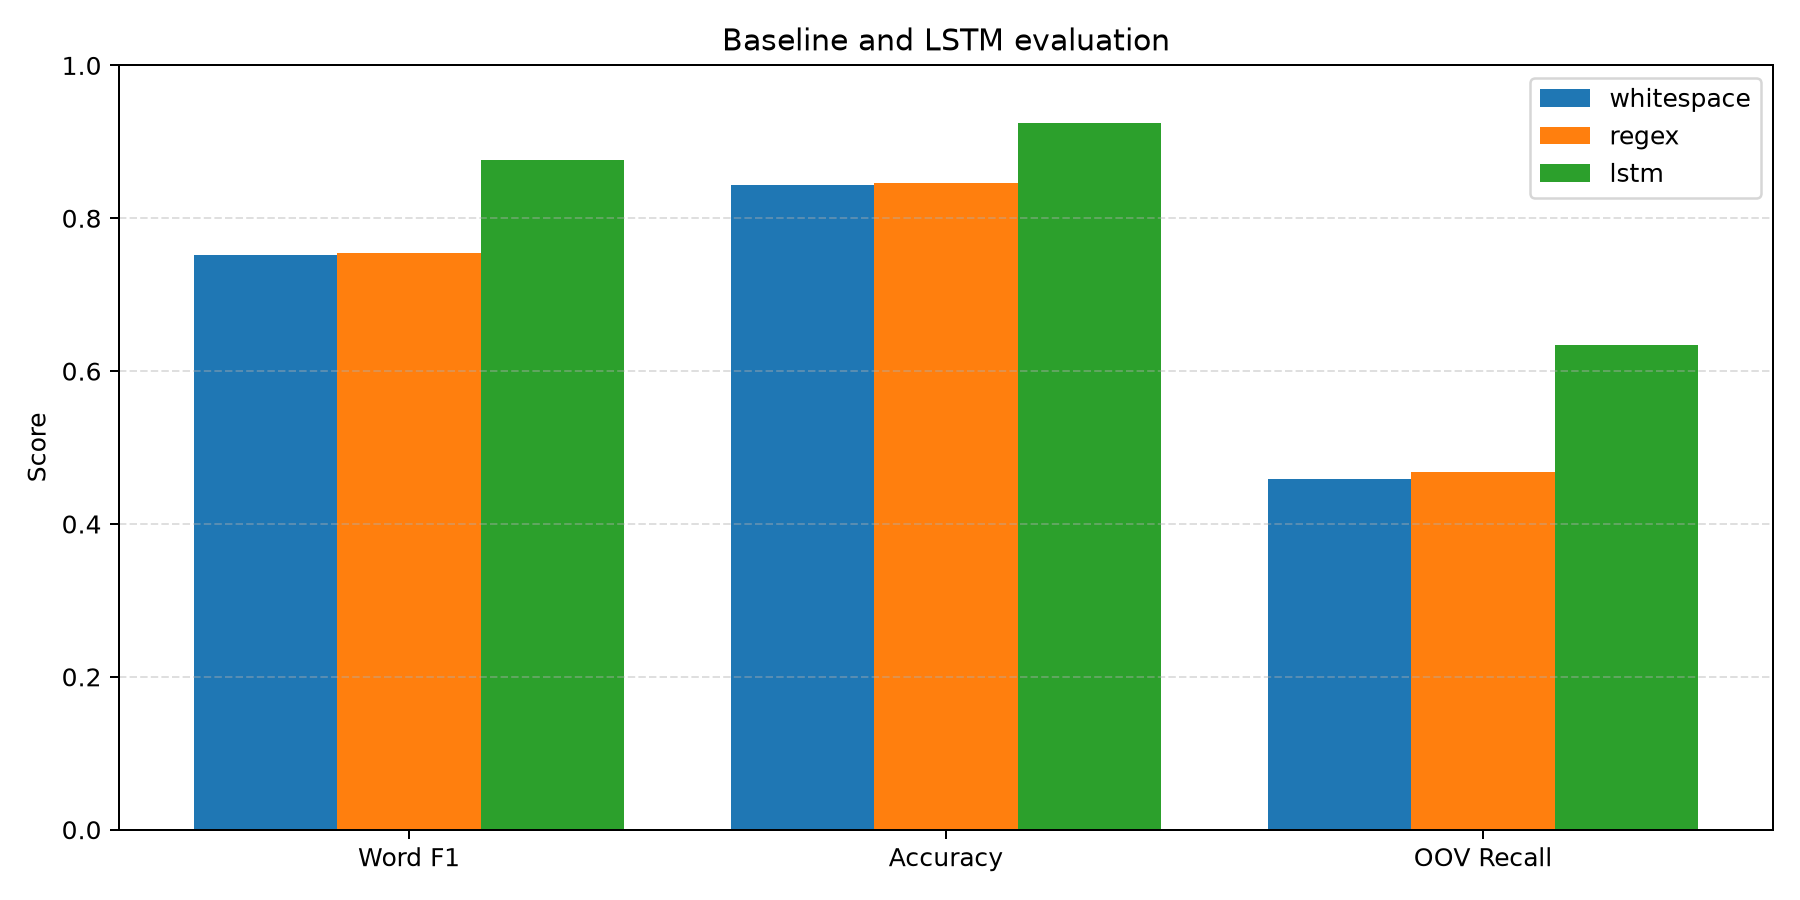

In [3]:
plot_path = results_dir / 'figures' / 'model_comparison.png'
if plot_path.exists():
    display(Image(filename=str(plot_path)))
else:
    print('Chưa có biểu đồ. Hãy chạy python scripts/evaluate.py.')

## Phân tích lỗi

Mỗi dòng trong CSV tương ứng với một câu mà dự đoán chưa khớp hoàn toàn với nhãn tham chiếu. Các cột từ Gold bị thiếu và từ Prediction thừa mô tả sai khác, không tự kết luận nguyên nhân lỗi.

In [4]:
if errors_path.exists():
    errors = pd.read_csv(errors_path)
    print(f'{len(errors)} dòng lỗi trên các mô hình đã đánh giá')
    display(errors.groupby('model').size().rename('incorrect_sentence_count').to_frame())
    display(errors.head(20))
else:
    print('Chưa có error_analysis.csv. Hãy chạy python scripts/evaluate.py.')

1901 dòng lỗi trên các mô hình đã đánh giá


,incorrect_sentence_count
model,
lstm,529
regex,685
whitespace,687


,model,id,text,gold_segmented,predicted_segmented,incorrect_gold_words,incorrect_predicted_words
0,whitespace,1,"Thanh bắt chuyện với Hùng và nói : "" Tôi trông...","Thanh bắt_chuyện với Hùng và nói : "" Tôi trông...","Thanh bắt chuyện với Hùng và nói : "" Tôi trông...",bắt_chuyện;quen_quen,bắt;chuyện;quen;quen
1,whitespace,2,"Hùng giật mình : "" Sao tôi không biết ông nhỉ ...","Hùng giật_mình : "" Sao tôi không biết ông nhỉ ...","Hùng giật mình : "" Sao tôi không biết ông nhỉ ...",giật_mình,giật;mình
2,whitespace,4,"À , tôi còn có danh sách lớp đây này "" .","À , tôi còn có danh_sách lớp đây này "" .","À , tôi còn có danh sách lớp đây này "" .",danh_sách,danh;sách
3,whitespace,5,Nói rồi Thanh giở danh sách lớp đọc vanh vách ...,Nói rồi Thanh giở danh_sách lớp đọc vanh_vách ...,Nói rồi Thanh giở danh sách lớp đọc vanh vách ...,danh_sách;vanh_vách;tên_tuổi;địa_chỉ;điện_thoại,danh;sách;vanh;vách;tên;tuổi;địa;chỉ;điện;thoại
4,whitespace,6,"Có lẽ vì lịch sự Hùng cũng nói : "" Tôi cũng th...","Có_lẽ vì lịch_sự Hùng cũng nói : "" Tôi cũng th...","Có lẽ vì lịch sự Hùng cũng nói : "" Tôi cũng th...",Có_lẽ;lịch_sự;hình_như,Có;lẽ;lịch;sự;hình;như
5,whitespace,7,"Như dự đoán của Thanh , mấy hôm sau Hùng gặp b...","Như dự_đoán của Thanh , mấy hôm sau Hùng gặp b...","Như dự đoán của Thanh , mấy hôm sau Hùng gặp b...",dự_đoán,dự;đoán
6,whitespace,8,"Có lẽ đã thấy đủ , bà Loan xách túi đi ra với ...","Có_lẽ đã thấy đủ , bà Loan xách túi đi ra với ...","Có lẽ đã thấy đủ , bà Loan xách túi đi ra với ...",Có_lẽ;ban_nhạc,Có;lẽ;ban;nhạc
7,whitespace,9,"Theo chân cửu vạn , chúng tôi đã chứng kiến co...","Theo chân cửu_vạn , chúng_tôi đã chứng_kiến co...","Theo chân cửu vạn , chúng tôi đã chứng kiến co...",cửu_vạn;chúng_tôi;chứng_kiến;vận_chuyển;sôi_độ...,cửu;vạn;chúng;tôi;chứng;kiến;vận;chuyển;sôi;độ...
8,whitespace,11,"Thanh đập vai Hùng hét to : "" cô ơi , hóa ra c...","Thanh đập vai Hùng hét to : "" cô ơi , hóa_ra c...","Thanh đập vai Hùng hét to : "" cô ơi , hóa ra c...",hóa_ra;tương_lai;tại_chức,hóa;ra;tương;lai;tại;chức
9,whitespace,12,"Bà Loan rành rẽ : "" mày chỉ huyên thuyên , anh...","Bà Loan rành_rẽ : "" mày chỉ huyên_thuyên , anh...","Bà Loan rành rẽ : "" mày chỉ huyên thuyên , anh...",rành_rẽ;huyên_thuyên;tốt_nghiệp,rành;rẽ;huyên;thuyên;tốt;nghiệp
